<a href="https://colab.research.google.com/github/thrka33/ITA0604-ML/blob/main/ML_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EXP 1 : Implement and demonstrate the FIND-S algorithm for finding the most specific hypothesis based on a given set of training data samples.  

In [ ]:
data = [
 ['Sunny','Warm','Normal','Strong','Warm','Same','Yes'],
 ['Sunny','Warm','High','Strong','Warm','Same','Yes'],
 ['Rainy','Cold','High','Strong','Warm','Change','No'],
 ['Sunny','Warm','High','Strong','Cool','Change','Yes']]
h = None
for row in data:
    if row[-1] == 'Yes':
        x = row[:-1]
        if h is None: h = x.copy()
        else: h = [a if a == b else '?' for a,b in zip(h,x)]
print("Final hypothesis:", h)

Final hypothesis: ['Sunny', 'Warm', '?', 'Strong', '?', '?']


EXP 2 : For a given set of training data examples stored in a .CSV file, implement and demonstrate the Candidate-Elimination algorithm in python to output a description of the set of all hypotheses consistent with the training examples

In [ ]:
import pandas as pd
from io import StringIO
csv = StringIO("""Sky,AirTemp,Humidity,Wind,Water,Forecast,Enjoy
Sunny,Warm,Normal,Strong,8Warm,Same,Yes
Sunny,Warm,High,Strong,Warm,Same,Yes
Rainy,Cold,High,Strong,Warm,Change,No
Sunny,Warm,High,Strong,Cool,Change,Yes
""")
df = pd.read_csv(csv)
X, y = df.iloc[:,:-1].values, df.iloc[:,-1].values
S = ['Ø']*X.shape[1]; G = [['?']*X.shape[1]]
for x, label in zip(X,y):
    if label == 'Yes':
        S = [v if s == 'Ø' or s == v else '?' for s,v in zip(S,x)]
        G = [g for g in G if all(a == '?' or a == b for a,b in zip(g,x))]
    else:
        new = []
        for g in G:
            for i,v in enumerate(x):
                if g[i] == '?' and S[i] not in ('Ø','?') and S[i] != v:
                    h = g.copy(); h[i] = S[i]; new.append(h)
        G = new
print("S boundary:", S)
print("G boundary:", G)

S boundary: ['Sunny', 'Warm', '?', 'Strong', '?', '?']
G boundary: [['Sunny', '?', '?', '?', '?', '?'], ['?', 'Warm', '?', '?', '?', '?']]


EXP 3 : Demonstrate the working of the decision tree based ID3 algorithm. Use an appropriate data set for building the decision tree and apply this knowledge to classify a new sample.

|--- petal width (cm) <= 0.80
|   |--- class: 0
|--- petal width (cm) >  0.80
|   |--- petal width (cm) <= 1.75
|   |   |--- petal length (cm) <= 4.95
|   |   |   |--- petal width (cm) <= 1.65
|   |   |   |   |--- class: 1
|   |   |   |--- petal width (cm) >  1.65
|   |   |   |   |--- class: 2
|   |   |--- petal length (cm) >  4.95
|   |   |   |--- petal width (cm) <= 1.55
|   |   |   |   |--- class: 2
|   |   |   |--- petal width (cm) >  1.55
|   |   |   |   |--- petal length (cm) <= 5.45
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- petal length (cm) >  5.45
|   |   |   |   |   |--- class: 2
|   |--- petal width (cm) >  1.75
|   |   |--- petal length (cm) <= 4.85
|   |   |   |--- sepal width (cm) <= 3.10
|   |   |   |   |--- class: 2
|   |   |   |--- sepal width (cm) >  3.10
|   |   |   |   |--- class: 1
|   |   |--- petal length (cm) >  4.85
|   |   |   |--- class: 2

Predicted class: setosa


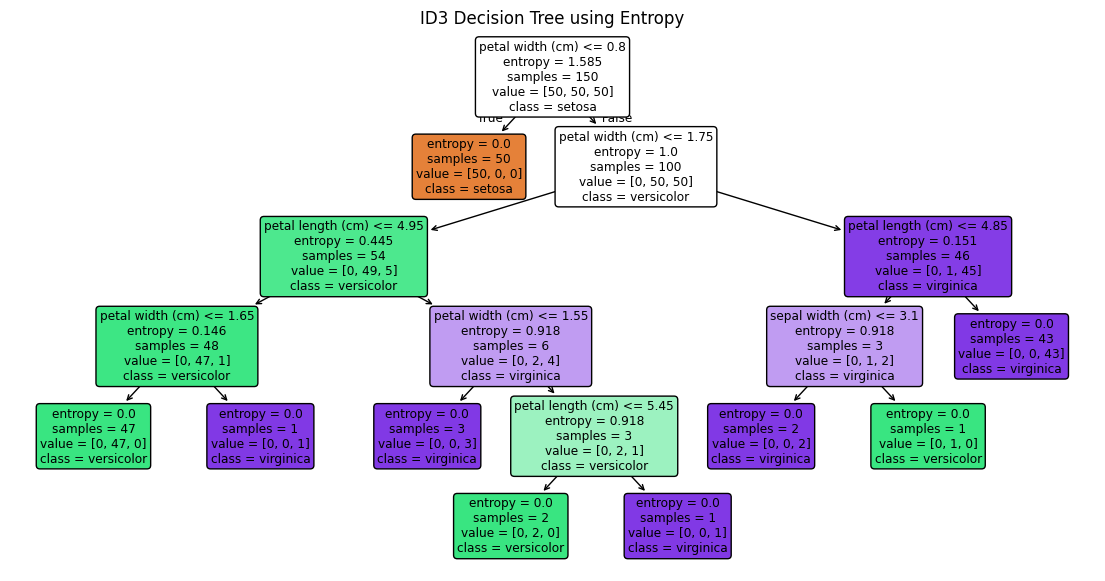

In [ ]:

from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
import matplotlib.pyplot as plt

d = load_iris()
m = DecisionTreeClassifier(criterion='entropy', random_state=0)
m.fit(d.data, d.target)

print(export_text(m, feature_names=list(d.feature_names)))
print("Predicted class:",
      d.target_names[m.predict([[5.1, 3.5, 1.4, 0.2]])[0]])

plt.figure(figsize=(14, 7))
plot_tree(m, feature_names=d.feature_names,
          class_names=d.target_names, filled=True, rounded=True)
plt.title("ID3 Decision Tree using Entropy")
plt.show()

EXP 4 : Build an Artificial Neural Network by implementing the Backpropagation algorithm and test the same using appropriate data sets.

Predictions: [0 1 1 0]


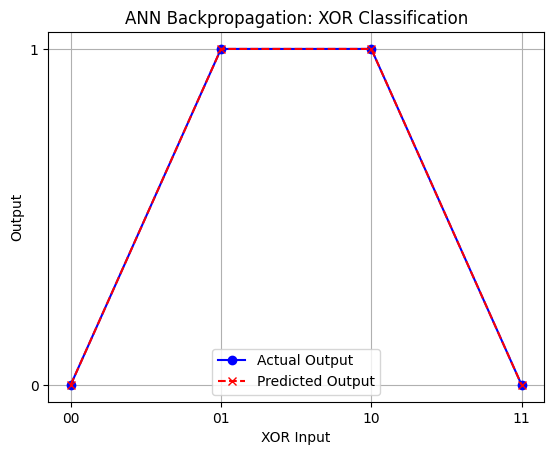

In [ ]:

from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt

X = [[0,0], [0,1], [1,0], [1,1]]
y = [0, 1, 1, 0]

m = MLPClassifier(hidden_layer_sizes=(4,), activation='tanh',
                  solver='lbfgs', max_iter=3000, random_state=1)
m.fit(X, y)
pred = m.predict(X)

print("Predictions:", pred)

plt.plot(range(4), y, 'bo-', label='Actual Output')
plt.plot(range(4), pred, 'rx--', label='Predicted Output')
plt.xticks(range(4), ['00', '01', '10', '11'])
plt.yticks([0, 1])
plt.xlabel("XOR Input")
plt.ylabel("Output")
plt.title("ANN Backpropagation: XOR Classification")
plt.legend()
plt.grid(True)
plt.show()

EXP 5:Write a program for Implementation of K-Nearest Neighbours (K-NN) in Python

Prediction: setosa


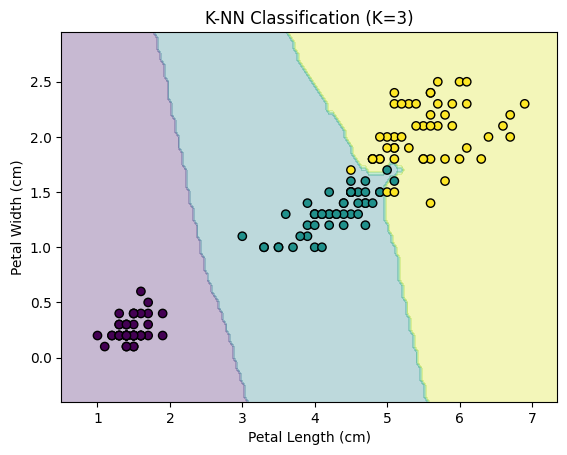

Training accuracy: 0.96


In [ ]:

from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
import numpy as np

d = load_iris()
X = d.data[:, 2:4]  # Petal length and width
y = d.target

m = KNeighborsClassifier(n_neighbors=3)
m.fit(X, y)

print("Prediction:",
      d.target_names[m.predict([[1.4, 0.2]])[0]])

# Create decision boundary grid
x1, x2 = np.meshgrid(
    np.arange(X[:, 0].min()-0.5, X[:, 0].max()+0.5, 0.05),
    np.arange(X[:, 1].min()-0.5, X[:, 1].max()+0.5, 0.05)
)

Z = m.predict(np.c_[x1.ravel(), x2.ravel()])
Z = Z.reshape(x1.shape)

plt.contourf(x1, x2, Z, alpha=0.3, cmap='viridis')
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='black',
            cmap='viridis')
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("K-NN Classification (K=3)")
plt.show()

# Original four-feature model accuracy
m4 = KNeighborsClassifier(n_neighbors=3).fit(d.data, d.target)
print("Training accuracy:", round(m4.score(d.data, d.target), 2))

EXP 6 : Write a program to implement Naïve Bayes algorithm in python and to display the results  using confusion matrix and accuracy.

Confusion Matrix:
 [[15  0  0]
 [ 0 14  1]
 [ 0  3 12]]
Accuracy: 0.911


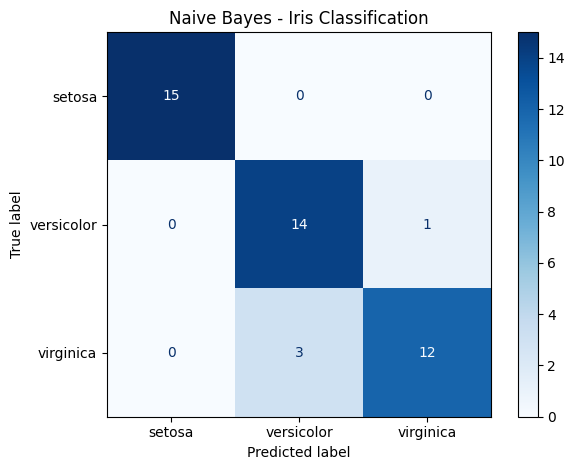

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Load Iris dataset

data = load_iris()
X = data.data
y = data.target

# Split dataset

X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.3, random_state=42, stratify=y
)

# Train Naive Bayes model

model = GaussianNB()
model.fit(X_train, y_train)

# Predict results

y_pred = model.predict(X_test)

# Display confusion matrix and accuracy

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))

# Plot confusion matrix

disp = ConfusionMatrixDisplay(
confusion_matrix=cm,
display_labels=data.target_names
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Naive Bayes - Iris Classification")
plt.tight_layout()
plt.show()


EXP 7 : Write a program to implement Logistic Regression (LR) algorithm in python

Accuracy: 0.933
Confusion Matrix:
 [[15  0  0]
 [ 0 14  1]
 [ 0  2 13]]


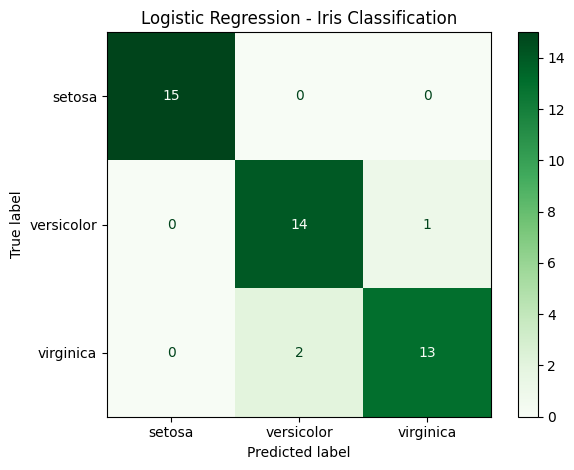

In [ ]:
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Load Iris dataset

data = load_iris()
X = data.data
y = data.target

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.3, random_state=42, stratify=y
)

# Train Logistic Regression model

model = LogisticRegression(max_iter=500)
model.fit(X_train, y_train)

# Predict flower species

y_pred = model.predict(X_test)

# Display accuracy

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", round(accuracy, 3))

# Display confusion matrix

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

# Visualize the confusion matrix

disp = ConfusionMatrixDisplay(
confusion_matrix=cm,
display_labels=data.target_names
)
disp.plot(cmap="Greens", values_format="d")
plt.title("Logistic Regression - Iris Classification")
plt.tight_layout()
plt.show()


EXP 8 : Write a program to implement Linear Regression (LR) algorithm in python

Prediction for X=6: 5.8
Slope: 0.6
Intercept: 2.2


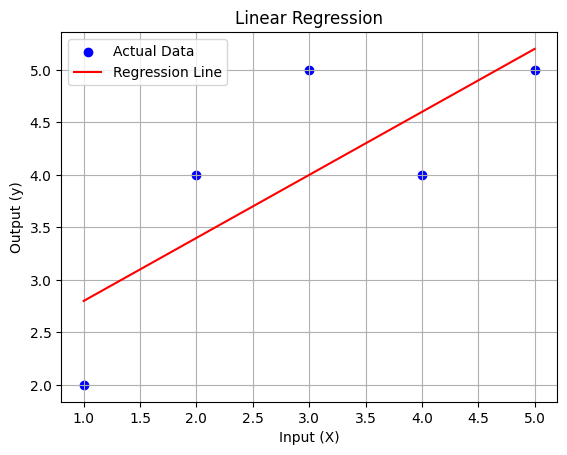

In [ ]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# Input and output data

X = [[1], [2], [3], [4], [5]]
y = [2, 4, 5, 4, 5]

# Train Linear Regression model

model = LinearRegression()
model.fit(X, y)

# Predict output for X = 6

prediction = model.predict([[6]])[0]

print("Prediction for X=6:", round(prediction, 2))
print("Slope:", round(model.coef_[0], 2))
print("Intercept:", round(model.intercept_, 2))

# Plot data and regression line

plt.scatter(X, y, color="blue", label="Actual Data")
plt.plot(X, model.predict(X), color="red", label="Regression Line")
plt.xlabel("Input (X)")
plt.ylabel("Output (y)")
plt.title("Linear Regression")
plt.legend()
plt.grid(True)
plt.show()


EXP 9 : Compare  Linear and Polynomial Regression using Python

Linear MSE: 6.22
Polynomial MSE: 0.0


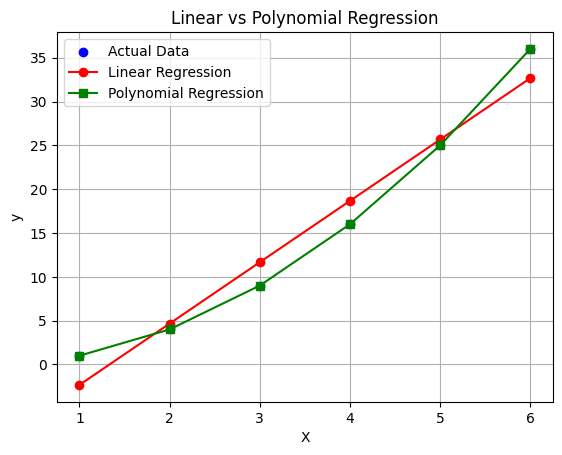

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# Input and output data

X = np.arange(1, 7).reshape(-1, 1)
y = np.array([1, 4, 9, 16, 25, 36])

# Linear Regression

linear = LinearRegression().fit(X, y)
y_linear = linear.predict(X)

# Polynomial Regression (degree 2)

poly = make_pipeline(
PolynomialFeatures(degree=2),
LinearRegression()
)
poly.fit(X, y)
y_poly = poly.predict(X)

# Compare Mean Squared Error

print("Linear MSE:", round(mean_squared_error(y, y_linear), 2))
print("Polynomial MSE:", round(mean_squared_error(y, y_poly), 2))

# Plot comparison

plt.scatter(X, y, color="blue", label="Actual Data")
plt.plot(X, y_linear, color="red", marker="o",
label="Linear Regression")
plt.plot(X, y_poly, color="green", marker="s",
label="Polynomial Regression")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.grid(True)
plt.show()


EXP 10 : Write a Python Program to Implement Expectation & Maximization Algorithm

Cluster labels: [1 1 1 0 0 0]
Cluster means: [5. 1.]


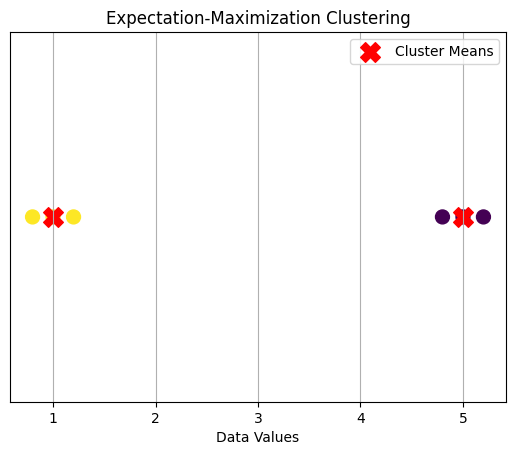

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

# Input data

X = np.array([1, 1.2, 0.8, 5, 5.2, 4.8]).reshape(-1, 1)

# Implement EM using Gaussian Mixture Model

model = GaussianMixture(n_components=2, random_state=0)
model.fit(X)

# Predict cluster labels

labels = model.predict(X)

print("Cluster labels:", labels)
print("Cluster means:", model.means_.ravel().round(2))

# Visualize clusters

plt.scatter(X.ravel(), np.zeros(len(X)),
c=labels, cmap="viridis", s=100)

plt.scatter(model.means_.ravel(), [0, 0],
color="red", marker="X", s=200, label="Cluster Means")

plt.xlabel("Data Values")
plt.yticks([])
plt.title("Expectation-Maximization Clustering")
plt.legend()
plt.grid(True)
plt.show()

EXP 11 :

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


Predicted category: High
Accuracy: 1.0


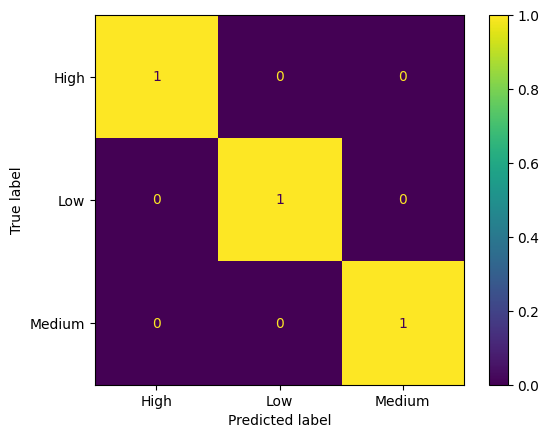

In [1]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

df = pd.DataFrame({
    'Income': [25,40,60,80,30,70,90,45,55,100,35,85],
    'Debt':   [80,60,40,20,70,30,10,55,45,5,75,15],
    'History':[1,2,4,5,1,4,5,2,3,5,1,4],
    'Score':  ['Low','Low','Medium','High','Low','High',
               'High','Medium','Medium','High','Low','High']
})

X = df[['Income','Debt','History']]
y = df['Score']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Predicted category:", model.predict([[65, 35, 4]])[0])
print("Accuracy:", accuracy_score(y_test, pred))
ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.show()

EXP 12 :

Accuracy: 1.0
Predicted flower: setosa


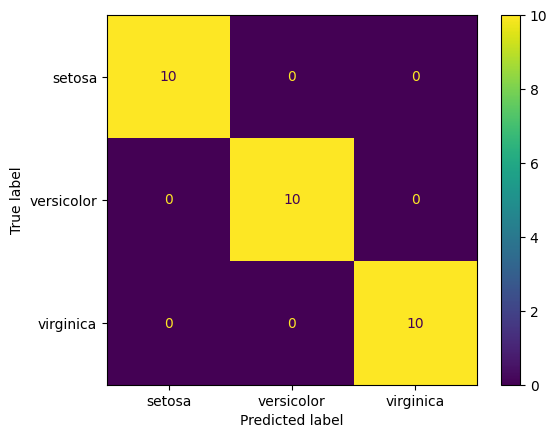

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.2,
    random_state=42, stratify=iris.target)

model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))
print("Predicted flower:", iris.target_names[
    model.predict([[5.1, 3.5, 1.4, 0.2]])[0]])
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=iris.target_names)
plt.show()

EXP 13 :

Predicted price: -119180.0
MAE: 10.0


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


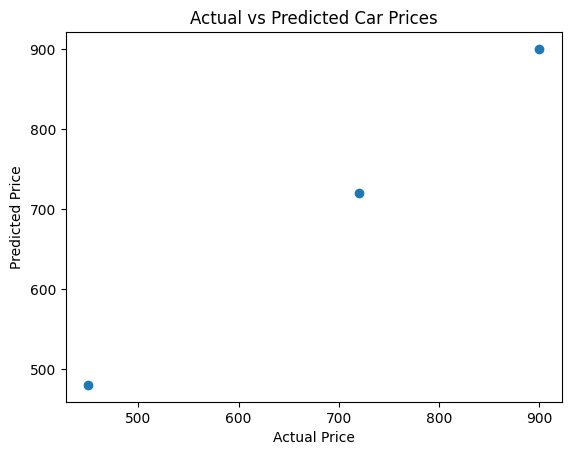

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

df = pd.DataFrame({
    'Age': [1,2,3,4,5,6,7,8,2,5,3,7],
    'Km':  [10,20,30,40,50,60,70,80,15,55,25,75],
    'Price':[900,800,700,600,500,400,300,200,820,450,720,280]
})

X = df[['Age','Km']]
y = df['Price']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)

print("Predicted price:", round(model.predict([[3, 30000]])[0], 2))
print("MAE:", round(mean_absolute_error(y_test, pred), 2))

plt.scatter(y_test, pred)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")
plt.show()

EXP 14 :

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


Predicted price: 46.36 lakhs
MAE: 6.15 lakhs


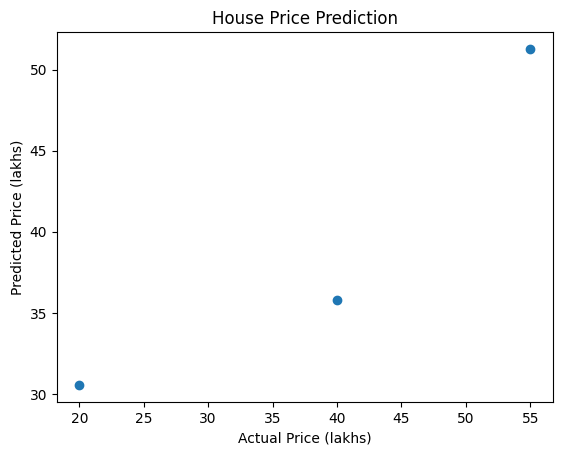

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

df = pd.DataFrame({
    'Area':[600,800,1000,1200,1400,1600,1800,2000,900,1500,1100,1900],
    'Bedrooms':[1,2,2,3,3,3,4,4,2,3,2,4],
    'Price':[20,28,35,45,50,58,68,75,32,55,40,72]
})

X = df[['Area','Bedrooms']]
y = df['Price']
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.25, random_state=42)

model = RandomForestRegressor(random_state=42).fit(Xtr, ytr)
pred = model.predict(Xte)

print("Predicted price:", round(model.predict([[1300, 3]])[0], 2),
      "lakhs")
print("MAE:", round(mean_absolute_error(yte, pred), 2), "lakhs")

plt.scatter(yte, pred)
plt.xlabel("Actual Price (lakhs)")
plt.ylabel("Predicted Price (lakhs)")
plt.title("House Price Prediction")
plt.show()

EXP 15:

Accuracy: 0.9666666666666667
Predicted flower: setosa


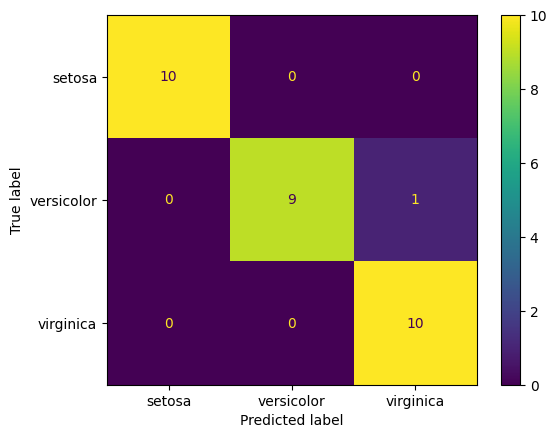

In [5]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

iris = load_iris()
Xtr, Xte, ytr, yte = train_test_split(
    iris.data, iris.target, test_size=0.2,
    random_state=42, stratify=iris.target)

model = GaussianNB().fit(Xtr, ytr)
pred = model.predict(Xte)

print("Accuracy:", accuracy_score(yte, pred))
print("Predicted flower:", iris.target_names[
    model.predict([[5.1, 3.5, 1.4, 0.2]])[0]])

ConfusionMatrixDisplay.from_predictions(
    yte, pred, display_labels=iris.target_names)
plt.show()

EXP 16 :

KNN Accuracy: 1.0
Decision Tree Accuracy: 0.933
Naive Bayes Accuracy: 0.967
Random Forest Accuracy: 0.9


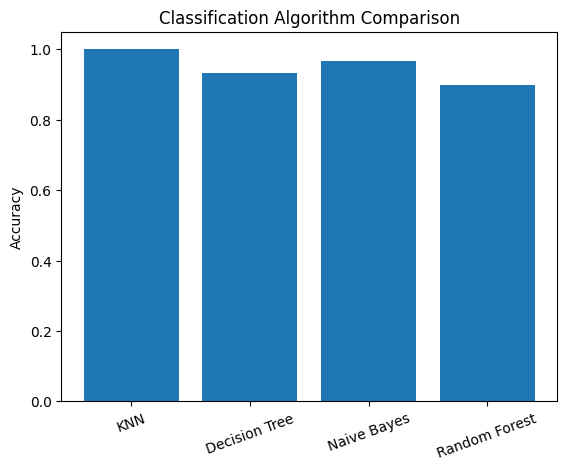

In [6]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

iris = load_iris()
Xtr, Xte, ytr, yte = train_test_split(
    iris.data, iris.target, test_size=0.2,
    random_state=42, stratify=iris.target)

models = {
    'KNN': KNeighborsClassifier(5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(random_state=42)
}

scores = {}
for name, model in models.items():
    model.fit(Xtr, ytr)
    scores[name] = accuracy_score(yte, model.predict(Xte))
    print(name, "Accuracy:", round(scores[name], 3))

plt.bar(scores.keys(), scores.values())
plt.ylabel("Accuracy")
plt.title("Classification Algorithm Comparison")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.show()

EXP 17 :

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


Predicted price range: 2


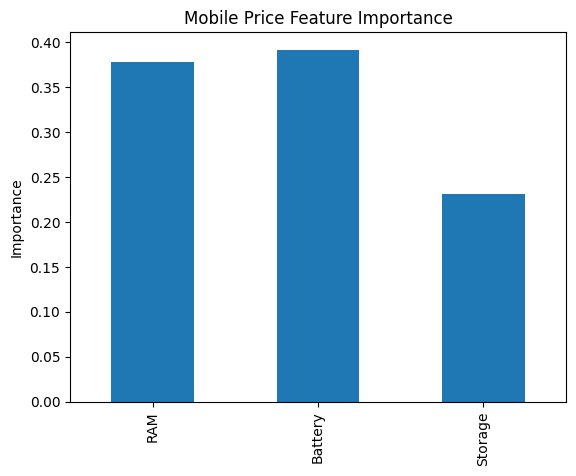

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

df = pd.DataFrame({
    'RAM':[2,3,4,4,6,6,8,8,3,4,6,8],
    'Battery':[2000,2500,3000,3500,4000,4500,5000,5500,
               2200,3200,4200,5200],
    'Storage':[16,32,32,64,64,128,128,256,16,64,128,256],
    'PriceRange':[0,0,1,1,2,2,3,3,0,1,2,3]
})

X = df[['RAM','Battery','Storage']]
y = df['PriceRange']

model = RandomForestClassifier(random_state=42).fit(X, y)
print("Predicted price range:",
      model.predict([[6, 4000, 128]])[0])

pd.Series(model.feature_importances_,
          index=X.columns).plot(kind='bar')
plt.title("Mobile Price Feature Importance")
plt.ylabel("Importance")
plt.show()

EXP 18 :

Accuracy: 0.8666666666666667
Predicted flower: setosa


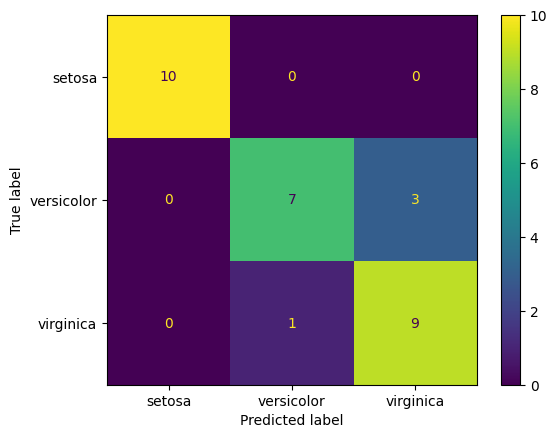

In [8]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

iris = load_iris()
Xtr, Xte, ytr, yte = train_test_split(
    iris.data, iris.target, test_size=0.2,
    random_state=42, stratify=iris.target)

scaler = StandardScaler()
Xtr = scaler.fit_transform(Xtr)
Xte = scaler.transform(Xte)

model = Perceptron(max_iter=1000, random_state=42)
model.fit(Xtr, ytr)
pred = model.predict(Xte)

print("Accuracy:", accuracy_score(yte, pred))
print("Predicted flower:", iris.target_names[
    model.predict(scaler.transform([[5.1, 3.5, 1.4, 0.2]]))[0]])

ConfusionMatrixDisplay.from_predictions(
    yte, pred, display_labels=iris.target_names)
plt.show()

EXP 19 :

Accuracy: 1.0
Loan prediction (1=Approved, 0=Rejected): 1


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


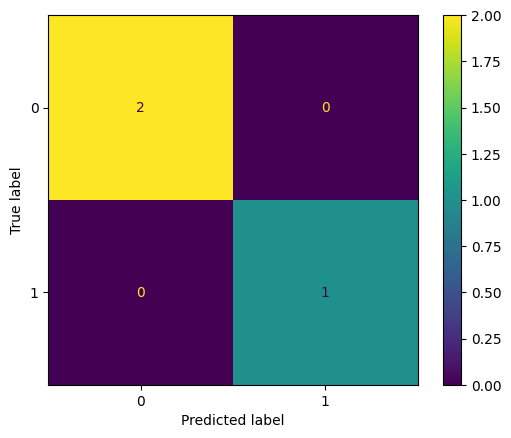

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

df = pd.DataFrame({
    'Income':[25,30,35,40,45,50,55,60,65,70,75,80],
    'CreditScore':[500,520,550,580,600,620,650,680,700,720,750,780],
    'Debt':[80,75,70,65,60,55,50,45,40,35,30,25],
    'LoanApproved':[0,0,0,0,0,1,0,1,1,1,1,1]
})

X = df[['Income','CreditScore','Debt']]
y = df['LoanApproved']

Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

model = GaussianNB().fit(Xtr, ytr)
pred = model.predict(Xte)

print("Accuracy:", accuracy_score(yte, pred))
print("Loan prediction (1=Approved, 0=Rejected):",
      model.predict([[65, 700, 40]])[0])

ConfusionMatrixDisplay.from_predictions(yte, pred)
plt.show()

EXP 20 :

Predicted sales for month 13: 181.82


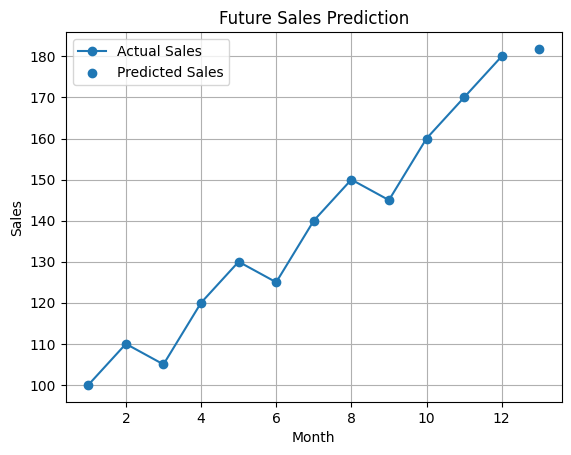

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

months = np.arange(1, 13).reshape(-1, 1)
sales = np.array([100,110,105,120,130,125,
                  140,150,145,160,170,180])

model = LinearRegression().fit(months, sales)
future_month = np.array([[13]])
prediction = model.predict(future_month)[0]

print("Predicted sales for month 13:", round(prediction, 2))

plt.plot(months.ravel(), sales, 'o-', label="Actual Sales")
plt.scatter([13], [prediction], label="Predicted Sales")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.title("Future Sales Prediction")
plt.legend()
plt.grid(True)
plt.show()